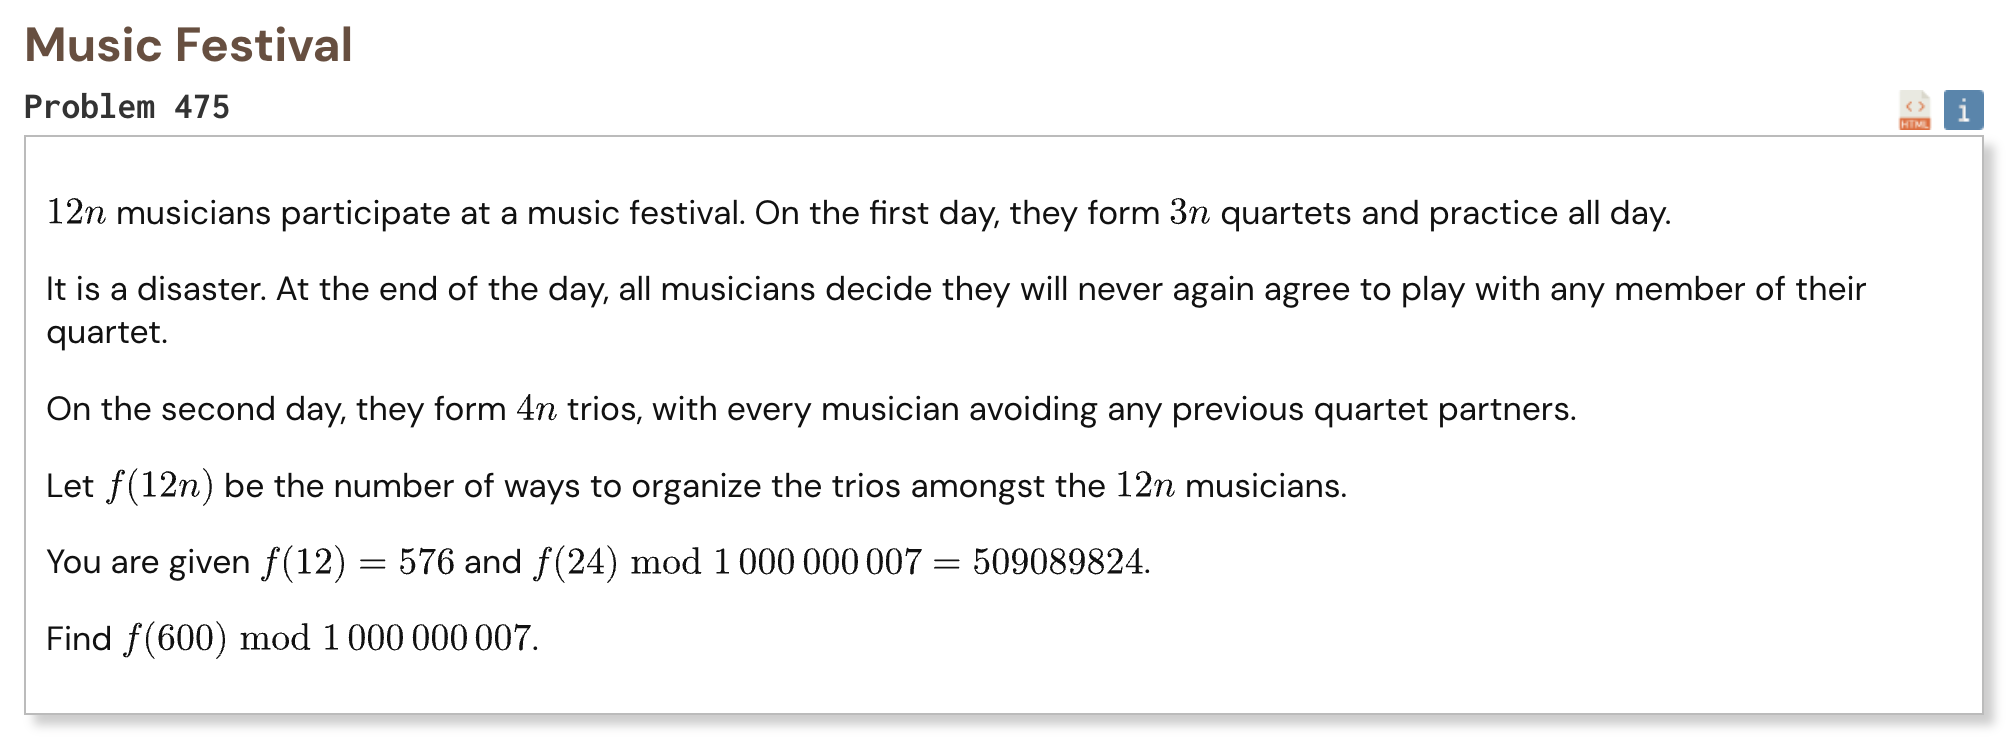

## Initial approach

- treat each original quartet as a group of four people who can never appear together again
- process the original quartets one at a time and build the new trios gradually
- keep track of incomplete trios containing one person and incomplete trios containing two people
- each new musician can finish an existing pair, join an existing single, or start a new single
- choose which open groups are used and assign the four distinct new musicians to them
- use dynamic programming on the numbers of open singles and pairs
- after all original quartets are processed, only the state with no incomplete trios is valid
- calculate everything modulo one billion and seven

In [1]:
%%time

from math import comb, factorial

MOD = 1_000_000_007
musicians = 600
quartets = musicians // 4

dp = {(0, 0): 1}

for _ in range(quartets):
    new_dp = {}

    for (singles, pairs), ways in dp.items():
        for close_pairs in range(min(4, pairs) + 1):
            remaining = 4 - close_pairs

            for join_singles in range(min(remaining, singles) + 1):
                new_singles = remaining - join_singles

                next_singles = singles - join_singles + new_singles
                next_pairs = pairs - close_pairs + join_singles

                choices = comb(pairs, close_pairs)
                choices *= factorial(4) // factorial(4 - close_pairs)

                choices *= comb(singles, join_singles)
                choices *= (
                    factorial(4 - close_pairs)
                    // factorial(new_singles)
                )

                state = (next_singles, next_pairs)

                new_dp[state] = (
                    new_dp.get(state, 0)
                    + ways * choices
                ) % MOD

    dp = new_dp

result = dp.get((0, 0), 0)

print("Result:", result)

Result: 75780067
CPU times: user 12.3 s, sys: 98.5 ms, total: 12.4 s
Wall time: 12.7 s
